In [ ]:
import pandas as pd
import numpy as np
from sklearn.datasets import make_blobs , make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

%matplotlib inline

In [ ]:
#Creating Dummy Data
#Generating 1000 Random data
x , y = make_blobs(n_samples = 1000 , centers=2 , n_features=2 , random_state=78)

In [ ]:
#Transforming

y = y.reshape(-1,1)
y.shape

(1000, 1)

In [ ]:
#Creating a Dataframe For our data
df = pd.DataFrame(x , columns=["Feature 1" , "Feature 2"])
df["Target"] = y
df.head(10)

,Feature 1,Feature 2,Target
0,5.478098,7.203714,1
1,-8.428483,4.121889,0
2,-7.905447,3.323639,0
3,6.411041,5.523013,1
4,7.288599,6.171226,1
5,5.281440,5.183203,1
6,-6.822188,4.297689,0
7,-9.753137,4.710871,0
8,-9.645101,3.001512,0
9,5.465926,7.140513,1


<Axes: xlabel='Feature 1', ylabel='Feature 2'>

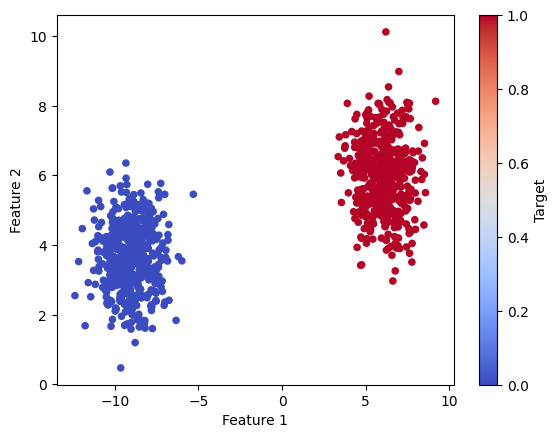

In [ ]:
df.plot(kind='scatter', x='Feature 1', y='Feature 2' , c='Target' , cmap='coolwarm')

In [ ]:
#Processing our data
x_train , x_test , y_train , y_test = train_test_split(x , y , random_state=1)

In [ ]:
#Scaling data and fitting
x_scaler = StandardScaler()
x_scaler.fit(x_train)

StandardScaler()

In [ ]:
#Scaling the data
x_train_scaled = x_scaler.transform(x_train)
x_test_scaled = x_scaler.transform(x_test)

**Nueral Network**

In [ ]:
#Creating a Neural Network Model
nueron = Sequential()

In [ ]:
#Steps to adding the first layer of Nueral Network
number_input = 2
number_hidden_nodes = 1
nueron.add(Dense(units=number_hidden_nodes , activation='relu' , input_dim=number_input))

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
#Adding Output Layer
number_classes = 1
nueron.add(Dense(units=number_classes , activation='sigmoid'))

In [ ]:
#Creating a Summary
nueron.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 1)                   │               3 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │               2 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5 (20.00 B)

 Trainable params: 5 (20.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Compiling Our Model
nueron.compile(loss='binary_crossentropy' , optimizer='adam' , metrics=['accuracy'])

In [ ]:
#Fitting The Model
model = nueron.fit(x_train_scaled , y_train , epochs=1000)

Epoch 1/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 1.0000 - loss: 1.5142e-06 
Epoch 2/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 1.0000 - loss: 1.4833e-06 
Epoch 3/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 1.0000 - loss: 1.3921e-06 
Epoch 4/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 1.4414e-06  
Epoch 5/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 1.0000 - loss: 1.3939e-06 
Epoch 6/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 1.4337e-06 
Epoch 7/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 1.0000 - loss: 1.3399e-06 
Epoch 8/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 1.0000 - loss: 1.4243e-06 
Epoch 9/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 1.0000 - loss: 1.3399e-06 
Epoch 10/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 1.0000 - loss: 1.3132e-06 
Epoch 11/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 1.2730e-

<Axes: >

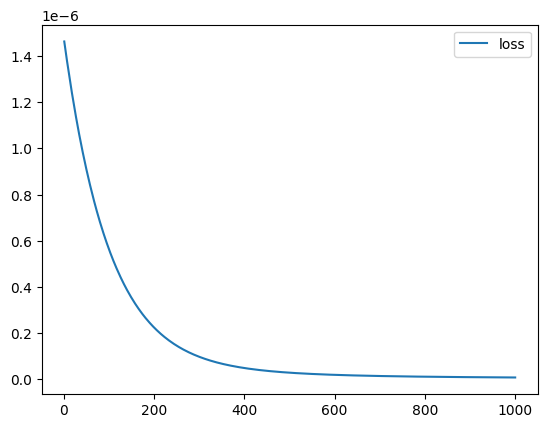

In [ ]:
#Evaluating the model with plot
df = pd.DataFrame(model.history ,index = range(1,len(model.history['loss'])+1))
df.plot(y='loss')

<Axes: >

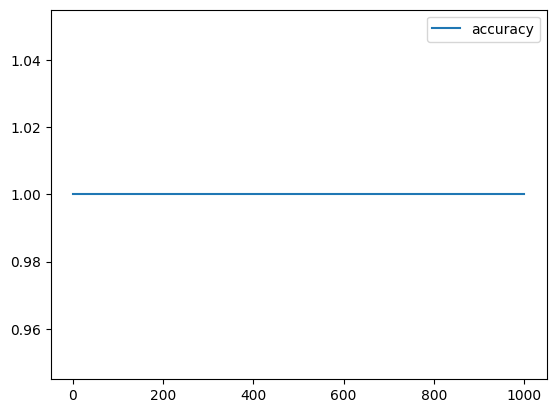

In [ ]:
#Data Accuracy plot
df.plot(y='accuracy')

In [26]:
#Evaluation Using Test data
#Evaluating data using fit linear dummy data
model_loss, model_accuracy = nueron.evaluate(x_test_scaled , y_test , verbose=2)
print(f"Loss : {model_loss} , Accuracy : {model_accuracy}")

8/8 - 0s - 3ms/step - accuracy: 1.0000 - loss: 7.9303e-09
Loss : 7.930294643188063e-09 , Accuracy : 1.0


In [28]:
#Making Predictions With New Data

#Creating new sample dummy data

new_x , new_y = make_blobs(n_samples=10 , centers=2 , n_features=2 , random_state=78)

In [38]:
#Making predictions

predictions = nueron.predict(new_x)
results = pd.DataFrame({"Predictions" : predictions.ravel() ,"Actual" : new_y})
results.head(10)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step


,Predictions,Actual
0,1.461419e-08,0
1,1.000000e+00,1
2,1.461419e-08,0
3,1.000000e+00,1
4,1.461419e-08,0
5,1.461419e-08,0
6,1.000000e+00,1
7,1.000000e+00,1
8,1.000000e+00,1
9,1.461419e-08,0


In [39]:
#Using a single nueron for Non-Linear Data

#Create dummy non-linear data
x_moon , y_moon = make_moons(n_samples=1000 , noise=0.08 , random_state=78)


In [40]:
#Reshape data
y_moon = y_moon.reshape(-1,1)

In [41]:
#Create Data frame and plot
df_moon = pd.DataFrame(x_moon , columns=["Feature 1" , "Feature 2"])
df_moon["Target"] = y_moon
df_moon.head(10)

,Feature 1,Feature 2,Target
0,0.676217,0.815220,0
1,1.487143,-0.210519,1
2,-1.027709,0.354966,0
3,0.236012,1.025531,0
4,1.856695,-0.042783,1
5,1.186913,-0.460725,1
6,1.886025,0.019076,1
7,1.402359,-0.406317,1
8,1.734996,-0.108911,1
9,1.787962,-0.116758,1


<Axes: xlabel='Feature 1', ylabel='Feature 2'>

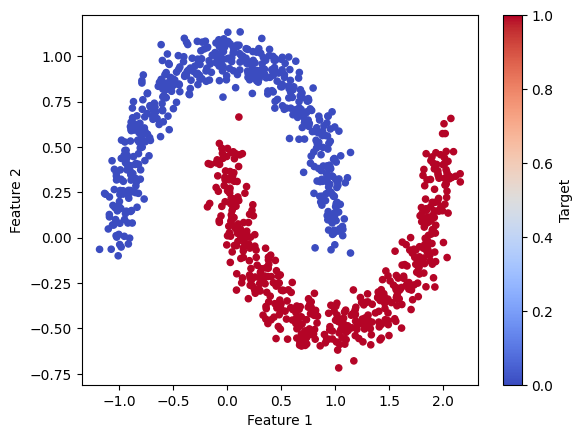

In [42]:
#Scatter Plot
df_moon.plot(kind='scatter', x='Feature 1', y='Feature 2' , c='Target' , cmap='coolwarm')

In [43]:
#Processing Data

#Create data training target and testing
x_moon_train , x_moon_test , y_moon_train , y_moon_test = train_test_split(x_moon , y_moon , random_state=78)

In [44]:
#Scaling Data
x_scaler_moon = StandardScaler()
x_scaler_moon.fit(x_moon_train)

StandardScaler()

In [45]:
#Transoforming

x_moon_train_scaled = x_scaler_moon.transform(x_moon_train)
x_moon_test_scaled = x_scaler_moon.transform(x_moon_test)

In [46]:
#Fitting the model with tensorflow

#Taining The model with Non-Linear data using  TensorFlow
model_moon = nueron.fit(x_moon_train_scaled , y_moon_train , epochs=1000)

Epoch 1/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6509 - loss: 3.7980 
Epoch 2/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6644 - loss: 3.6399 
Epoch 3/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6696 - loss: 3.5105 
Epoch 4/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6877 - loss: 3.1924 
Epoch 5/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6983 - loss: 2.9605 
Epoch 6/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6915 - loss: 3.1205
Epoch 7/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6929 - loss: 2.8719
Epoch 8/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6830 - loss: 3.1223
Epoch 9/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7033 - loss: 2.5733
Epoch 10/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7223 - loss: 2.5771
Epoch 11/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6924 - loss: 2.6875
Epoch 12/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms

<Axes: >

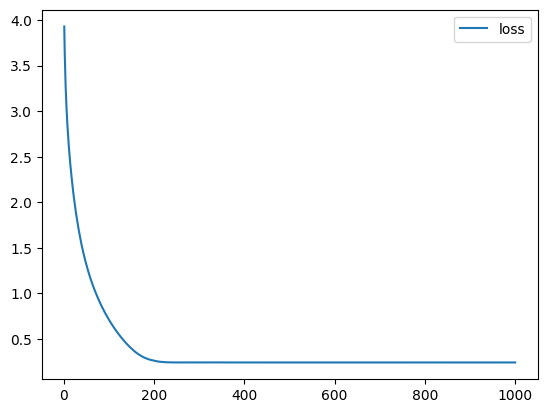

In [47]:
#Evaluating The model

#Create data frame history plot
df_moon = pd.DataFrame(model_moon.history ,index = range(1,len(model_moon.history['loss'])+1))
df_moon.plot(y='loss')

<Axes: >

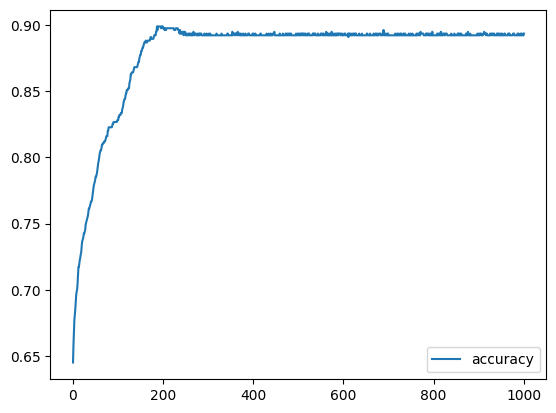

In [48]:
#Data accuracy plot
df_moon.plot(y='accuracy')

In [49]:
#Evaluating the model using test data

model_moon_loss, model_moon_accuracy = nueron.evaluate(x_moon_test_scaled , y_moon_test , verbose=2)
print(f"Loss : {model_moon_loss} , Accuracy : {model_moon_accuracy}")

8/8 - 0s - 6ms/step - accuracy: 0.8600 - loss: 0.2521
Loss : 0.25206679105758667 , Accuracy : 0.8600000143051147


In [50]:
#Creating test data
x_moon_new , y_moon_new = make_moons(n_samples=10 , noise=0.08 , random_state=78)

In [52]:
#Making Predictions
predictions_moon = nueron.predict(x_moon_new)
results_moon = pd.DataFrame({"Predictions" : predictions_moon.ravel() ,"Actual" : y_moon_new})
results_moon.head(10)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


,Predictions,Actual
0,0.040755,0
1,0.041025,0
2,0.174990,0
3,0.711324,1
4,0.876541,1
5,0.131592,0
6,0.663584,0
7,0.928972,1
8,0.690646,1
9,0.103386,1
